In [1]:
# imports
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor


In [2]:
#Download and prepare the data 
data_root = "https://github.com/ageron/data/raw/main/" 
lifesat = pd.read_csv(data_root + "lifesat/lifesat.csv")
x = lifesat[["GDP per capita (USD)"]].values
y = lifesat[["Life satisfaction"]].values


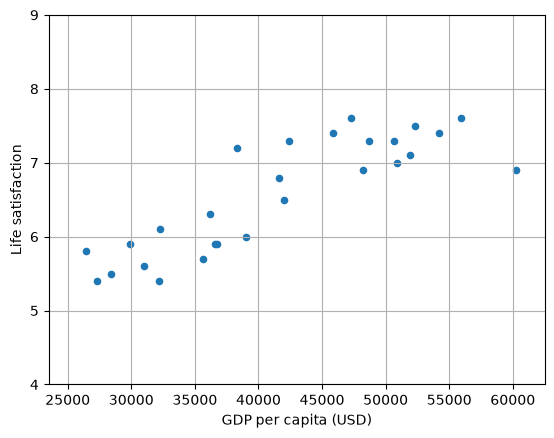

In [3]:
# Visualize the data 
lifesat.plot(kind= 'scatter', grid = True, x = "GDP per capita (USD)",
              y = "Life satisfaction")
plt.axis([23_500, 62_500, 4, 9])
plt.show()


In [4]:
# model selection 
model = LinearRegression()
model2 = KNeighborsRegressor(n_neighbors=3) # nearest 3 neighbours 
model2.fit(x,y)
model.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[0.]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3.75]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[49110.96]


In [5]:
# Make a prediction for Cyprus
X_new = [[37_655.2]] # Cyprus' GDP per capita in 2020
print(model.predict(X_new)) # output: [[6.30165767]]
print(model2.predict(X_new))

[[6.30165767]]
[[6.33333333]]


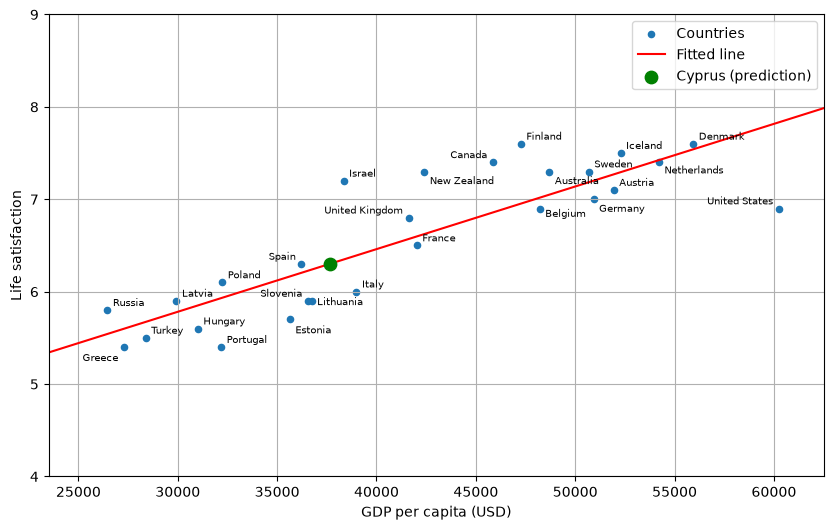

Life satisfaction = 3.75 + 0.0000678 × GDP per capita


In [6]:
# Visualize the fitted line
ax = lifesat.plot(kind="scatter", grid=True, x="GDP per capita (USD)",
                  y="Life satisfaction", label="Countries", figsize=(10, 6))

x_line = np.array([[23_500], [62_500]])
y_line = model.predict(x_line)
ax.plot(x_line, y_line, color="red", label="Fitted line")

ax.scatter(X_new, model.predict(X_new), color="green", s=80, zorder=3,
           label="Cyprus (prediction)")

# Write each country's name next to its point
# Countries listed here get a custom position so their names don't overlap
label_offsets = {"Greece": (-4, -10), "Spain": (-4, 3), "Estonia": (4, -10),
                 "Slovenia": (-4, 3), "Lithuania": (4, -3), "United Kingdom": (-4, 3),
                 "New Zealand": (4, -9), "Canada": (-4, 3), "Belgium": (4, -6),
                 "Australia": (4, -9), "Germany": (4, -9), "Netherlands": (4, -8),
                 "United States": (-4, 3)}

for country, gdp, satisfaction in lifesat.itertuples(index=False):
    dx, dy = label_offsets.get(country, (4, 3))
    ax.annotate(country, (gdp, satisfaction), xytext=(dx, dy),
                textcoords="offset points", fontsize=7,
                ha="right" if dx < 0 else "left")

plt.axis([23_500, 62_500, 4, 9])
plt.legend()
plt.show()

print(f"Life satisfaction = {model.intercept_[0]:.2f} + {model.coef_[0][0]:.7f} × GDP per capita")